# 10 minutes to pandas

This is a short introduction to pandas, geared mainly for new users. You can see more complex recipes in the Cookbook.

Customarily, we import as follows:

In [1]:
import numpy as np
import pandas as pd

## Basic data structures in pandas

pandas provides two types of classes for handling data:

1. `Series`: a one-dimensional labeled array holding data of any type such as integers, strings, Python objects etc.
2. `DataFrame`: a two-dimensional data structure that holds data like a two-dimension array or a table with rows and columns.

## Object creation

Creating a `Series` by passing a list of values, letting pandas create a default `RangeIndex`.

In [2]:
s = pd.Series([1, 3, 5, np.nan, 6, 8])
s

0    1.0
1    3.0
2    5.0
3    NaN
4    6.0
5    8.0
dtype: float64

Creating a `DataFrame` by passing a NumPy array with a datetime index using `date_range()` and labeled columns:

In [3]:
dates = pd.date_range("20130101", periods=6)
dates

DatetimeIndex(['2013-01-01', '2013-01-02', '2013-01-03', '2013-01-04',
               '2013-01-05', '2013-01-06'],
              dtype='datetime64[us]', freq='D')

In [4]:
df = pd.DataFrame(np.random.randn(6, 4), index=dates, columns=list("ABCD"))
df

,A,B,C,D
2013-01-01,-1.442924,-0.281470,-1.326412,-0.069578
2013-01-02,-0.254150,0.613209,0.706385,0.084123
2013-01-03,-0.550042,0.163813,-0.923696,0.703057
2013-01-04,-0.871771,-0.811761,-0.068345,0.619288
2013-01-05,-0.531100,-1.397552,1.161470,-1.000906
2013-01-06,-0.563640,-0.027269,-0.152290,1.170564


Creating a `DataFrame` by passing a dictionary of objects where the keys are the column labels and the values are the column values.

In [5]:
df2 = pd.DataFrame(
    {
        "A": 1.0,
        "B": pd.Timestamp("20130102"),
        "C": pd.Series(1, index=list(range(4)), dtype="float32"),
        "D": np.array([3] * 4, dtype="int32"),
        "E": pd.Categorical(["test", "train", "test", "train"]),
        "F": "foo",
    }
)
df2

,A,B,C,D,E,F
0,1.0,2013-01-02,1.0,3,test,foo
1,1.0,2013-01-02,1.0,3,train,foo
2,1.0,2013-01-02,1.0,3,test,foo
3,1.0,2013-01-02,1.0,3,train,foo


The columns of the resulting `DataFrame` have different dtypes:

In [6]:
df2.dtypes

A           float64
B    datetime64[us]
C           float32
D             int32
E          category
F               str
dtype: object

If you're using IPython, tab completion for column names (as well as public attributes) is automatically enabled. Here's a subset of the attributes that will be completed:

```
df2.<TAB>  # noqa: E225, E999
df2.A                  df2.bool
df2.abs                df2.boxplot
df2.add                df2.C
df2.add_prefix         df2.clip
df2.add_suffix         df2.columns
df2.align              df2.copy
df2.all                df2.count
df2.any                df2.combine
df2.append             df2.D
df2.apply              df2.describe
df2.B                  df2.duplicated
df2.diff
```

As you can see, the columns `A`, `B`, `C`, and `D` are automatically tab completed. `E` and `F` are there as well; the rest of the attributes have been truncated for brevity.

## Viewing data

Use `DataFrame.head()` and `DataFrame.tail()` to view the top and bottom rows of the frame respectively:

In [7]:
df.head()

,A,B,C,D
2013-01-01,-1.442924,-0.281470,-1.326412,-0.069578
2013-01-02,-0.254150,0.613209,0.706385,0.084123
2013-01-03,-0.550042,0.163813,-0.923696,0.703057
2013-01-04,-0.871771,-0.811761,-0.068345,0.619288
2013-01-05,-0.531100,-1.397552,1.161470,-1.000906


In [8]:
df.tail(3)

,A,B,C,D
2013-01-04,-0.871771,-0.811761,-0.068345,0.619288
2013-01-05,-0.531100,-1.397552,1.161470,-1.000906
2013-01-06,-0.563640,-0.027269,-0.152290,1.170564


Display the `DataFrame.index` or `DataFrame.columns`:

In [9]:
df.index

DatetimeIndex(['2013-01-01', '2013-01-02', '2013-01-03', '2013-01-04',
               '2013-01-05', '2013-01-06'],
              dtype='datetime64[us]', freq='D')

In [10]:
df.columns

Index(['A', 'B', 'C', 'D'], dtype='str')

Return a NumPy representation of the underlying data with `DataFrame.to_numpy()` without the index or column labels:

In [11]:
df.to_numpy()

array([[-1.44292414, -0.28146951, -1.32641167, -0.06957813],
       [-0.25415009,  0.61320853,  0.70638526,  0.08412281],
       [-0.55004239,  0.16381274, -0.92369645,  0.70305744],
       [-0.87177107, -0.81176084, -0.06834503,  0.61928781],
       [-0.5311001 , -1.39755176,  1.16146987, -1.00090564],
       [-0.5636401 , -0.02726888, -0.15229024,  1.1705642 ]])

**Note**

NumPy arrays have one dtype for the entire array while pandas DataFrames have one dtype per column. When you call `DataFrame.to_numpy()`, pandas will find the NumPy dtype that can hold *all* of the dtypes in the DataFrame. If the common data type is `object`, `DataFrame.to_numpy()` will require copying data.

In [12]:
df2.dtypes

A           float64
B    datetime64[us]
C           float32
D             int32
E          category
F               str
dtype: object

In [13]:
df2.to_numpy()

array([[1.0, Timestamp('2013-01-02 00:00:00'), 1.0, 3, 'test', 'foo'],
       [1.0, Timestamp('2013-01-02 00:00:00'), 1.0, 3, 'train', 'foo'],
       [1.0, Timestamp('2013-01-02 00:00:00'), 1.0, 3, 'test', 'foo'],
       [1.0, Timestamp('2013-01-02 00:00:00'), 1.0, 3, 'train', 'foo']],
      dtype=object)

`describe()` shows a quick statistic summary of your data:

In [14]:
df.describe()

,A,B,C,D
count,6.000000,6.000000,6.000000,6.000000
mean,-0.702271,-0.290172,-0.100481,0.251091
std,0.412262,0.719686,0.941048,0.759405
min,-1.442924,-1.397552,-1.326412,-1.000906
25%,-0.794738,-0.679188,-0.730845,-0.031153
50%,-0.556841,-0.154369,-0.110318,0.351705
75%,-0.535836,0.116042,0.512703,0.682115
max,-0.254150,0.613209,1.161470,1.170564


Transposing your data:

In [15]:
df.T

,2013-01-01,2013-01-02,2013-01-03,2013-01-04,2013-01-05,2013-01-06
A,-1.442924,-0.254150,-0.550042,-0.871771,-0.531100,-0.563640
B,-0.281470,0.613209,0.163813,-0.811761,-1.397552,-0.027269
C,-1.326412,0.706385,-0.923696,-0.068345,1.161470,-0.152290
D,-0.069578,0.084123,0.703057,0.619288,-1.000906,1.170564


`DataFrame.sort_index()` sorts by an axis:

In [16]:
df.sort_index(axis=1, ascending=False)

,D,C,B,A
2013-01-01,-0.069578,-1.326412,-0.281470,-1.442924
2013-01-02,0.084123,0.706385,0.613209,-0.254150
2013-01-03,0.703057,-0.923696,0.163813,-0.550042
2013-01-04,0.619288,-0.068345,-0.811761,-0.871771
2013-01-05,-1.000906,1.161470,-1.397552,-0.531100
2013-01-06,1.170564,-0.152290,-0.027269,-0.563640


`DataFrame.sort_values()` sorts by values:

In [17]:
df.sort_values(by="B")

,A,B,C,D
2013-01-05,-0.531100,-1.397552,1.161470,-1.000906
2013-01-04,-0.871771,-0.811761,-0.068345,0.619288
2013-01-01,-1.442924,-0.281470,-1.326412,-0.069578
2013-01-06,-0.563640,-0.027269,-0.152290,1.170564
2013-01-03,-0.550042,0.163813,-0.923696,0.703057
2013-01-02,-0.254150,0.613209,0.706385,0.084123


## Selection

**Note**

While standard Python / NumPy expressions for selecting and setting are intuitive and come in handy for interactive work, for production code, we recommend the optimized pandas data access methods, `DataFrame.at()`, `DataFrame.iat()`, `DataFrame.loc()` and `DataFrame.iloc()`.

### Getitem (`[]`)

For a `DataFrame`, passing a single label selects a column and yields a `Series`:

In [18]:
df["A"]

2013-01-01   -1.442924
2013-01-02   -0.254150
2013-01-03   -0.550042
2013-01-04   -0.871771
2013-01-05   -0.531100
2013-01-06   -0.563640
Freq: D, Name: A, dtype: float64

If the label only contains letters, numbers, and underscores, you can alternatively use the column name attribute:

In [19]:
df.A

2013-01-01   -1.442924
2013-01-02   -0.254150
2013-01-03   -0.550042
2013-01-04   -0.871771
2013-01-05   -0.531100
2013-01-06   -0.563640
Freq: D, Name: A, dtype: float64

Passing a list of column labels selects multiple columns, which can be useful for getting a subset/rearranging:

In [20]:
df[["B", "A"]]

,B,A
2013-01-01,-0.281470,-1.442924
2013-01-02,0.613209,-0.254150
2013-01-03,0.163813,-0.550042
2013-01-04,-0.811761,-0.871771
2013-01-05,-1.397552,-0.531100
2013-01-06,-0.027269,-0.563640


For a `DataFrame`, passing a slice `:` selects matching rows:

In [21]:
df[0:3]

,A,B,C,D
2013-01-01,-1.442924,-0.281470,-1.326412,-0.069578
2013-01-02,-0.254150,0.613209,0.706385,0.084123
2013-01-03,-0.550042,0.163813,-0.923696,0.703057


In [22]:
df["20130102":"20130104"]

,A,B,C,D
2013-01-02,-0.254150,0.613209,0.706385,0.084123
2013-01-03,-0.550042,0.163813,-0.923696,0.703057
2013-01-04,-0.871771,-0.811761,-0.068345,0.619288


### Selection by label

Selecting a row matching a label:

In [23]:
df.loc[dates[0]]

A   -1.442924
B   -0.281470
C   -1.326412
D   -0.069578
Name: 2013-01-01 00:00:00, dtype: float64

Selecting all rows (`:`) with a select column labels:

In [24]:
df.loc[:, ["A", "B"]]

,A,B
2013-01-01,-1.442924,-0.281470
2013-01-02,-0.254150,0.613209
2013-01-03,-0.550042,0.163813
2013-01-04,-0.871771,-0.811761
2013-01-05,-0.531100,-1.397552
2013-01-06,-0.563640,-0.027269


For label slicing, both endpoints are *included*:

In [25]:
df.loc["20130102":"20130104", ["A", "B"]]

,A,B
2013-01-02,-0.254150,0.613209
2013-01-03,-0.550042,0.163813
2013-01-04,-0.871771,-0.811761


Selecting a single row and column label returns a scalar:

In [26]:
df.loc[dates[0], "A"]

np.float64(-1.442924136874906)

For getting fast access to a scalar (equivalent to the prior method):

In [27]:
df.at[dates[0], "A"]

np.float64(-1.442924136874906)

### Selection by position

Select via the position of the passed integers:

In [28]:
df.iloc[3]

A   -0.871771
B   -0.811761
C   -0.068345
D    0.619288
Name: 2013-01-04 00:00:00, dtype: float64

Integer slices acts similar to NumPy/Python:

In [29]:
df.iloc[3:5, 0:2]

,A,B
2013-01-04,-0.871771,-0.811761
2013-01-05,-0.531100,-1.397552


Lists of integer position locations:

In [30]:
df.iloc[[1, 2, 4], [0, 2]]

,A,C
2013-01-02,-0.254150,0.706385
2013-01-03,-0.550042,-0.923696
2013-01-05,-0.531100,1.161470


For slicing rows explicitly:

In [31]:
df.iloc[1:3, :]

,A,B,C,D
2013-01-02,-0.254150,0.613209,0.706385,0.084123
2013-01-03,-0.550042,0.163813,-0.923696,0.703057


For slicing columns explicitly:

In [32]:
df.iloc[:, 1:3]

,B,C
2013-01-01,-0.281470,-1.326412
2013-01-02,0.613209,0.706385
2013-01-03,0.163813,-0.923696
2013-01-04,-0.811761,-0.068345
2013-01-05,-1.397552,1.161470
2013-01-06,-0.027269,-0.152290


For getting a value explicitly:

In [33]:
df.iloc[1, 1]

np.float64(0.6132085280369166)

For getting fast access to a scalar (equivalent to the prior method):

In [34]:
df.iat[1, 1]

np.float64(0.6132085280369166)

### Boolean indexing

Select rows where `df.A` is greater than `0`.

In [35]:
df[df["A"] > 0]

,A,B,C,D


Selecting values from a `DataFrame` where a boolean condition is met:

In [36]:
df[df > 0]

,A,B,C,D
2013-01-01,NaN,NaN,NaN,NaN
2013-01-02,NaN,0.613209,0.706385,0.084123
2013-01-03,NaN,0.163813,NaN,0.703057
2013-01-04,NaN,NaN,NaN,0.619288
2013-01-05,NaN,NaN,1.161470,NaN
2013-01-06,NaN,NaN,NaN,1.170564


Using `isin()` method for filtering:

In [37]:
df2 = df.copy()
df2["E"] = ["one", "one", "two", "three", "four", "three"]
df2

,A,B,C,D,E
2013-01-01,-1.442924,-0.281470,-1.326412,-0.069578,one
2013-01-02,-0.254150,0.613209,0.706385,0.084123,one
2013-01-03,-0.550042,0.163813,-0.923696,0.703057,two
2013-01-04,-0.871771,-0.811761,-0.068345,0.619288,three
2013-01-05,-0.531100,-1.397552,1.161470,-1.000906,four
2013-01-06,-0.563640,-0.027269,-0.152290,1.170564,three


In [38]:
df2[df2["E"].isin(["two", "four"])]

,A,B,C,D,E
2013-01-03,-0.550042,0.163813,-0.923696,0.703057,two
2013-01-05,-0.531100,-1.397552,1.161470,-1.000906,four


### Setting

Setting a new column automatically aligns the data by the indexes:

In [39]:
s1 = pd.Series(
    [1, 2, 3, 4, 5, 6],
    index=pd.date_range("20130102", periods=6))
s1

2013-01-02    1
2013-01-03    2
2013-01-04    3
2013-01-05    4
2013-01-06    5
2013-01-07    6
Freq: D, dtype: int64

In [40]:
df["F"] = s1

Setting values by label:

In [41]:
df.at[dates[0], "A"] = 0

Setting values by position:

In [42]:
df.iat[0, 1] = 0

Setting by assigning with a NumPy array:

In [43]:
df.loc[:, "D"] = np.array([5] * len(df))

The result of the prior setting operations:

In [44]:
df

,A,B,C,D,F
2013-01-01,0.000000,0.000000,-1.326412,5.0,NaN
2013-01-02,-0.254150,0.613209,0.706385,5.0,1.0
2013-01-03,-0.550042,0.163813,-0.923696,5.0,2.0
2013-01-04,-0.871771,-0.811761,-0.068345,5.0,3.0
2013-01-05,-0.531100,-1.397552,1.161470,5.0,4.0
2013-01-06,-0.563640,-0.027269,-0.152290,5.0,5.0


A `where` operation with setting:

In [45]:
df2 = df.copy()
df2[df2 > 0] = -df2
df2

,A,B,C,D,F
2013-01-01,0.000000,0.000000,-1.326412,-5.0,NaN
2013-01-02,-0.254150,-0.613209,-0.706385,-5.0,-1.0
2013-01-03,-0.550042,-0.163813,-0.923696,-5.0,-2.0
2013-01-04,-0.871771,-0.811761,-0.068345,-5.0,-3.0
2013-01-05,-0.531100,-1.397552,-1.161470,-5.0,-4.0
2013-01-06,-0.563640,-0.027269,-0.152290,-5.0,-5.0


## Missing data

For NumPy data types, `np.nan` represents missing data. It is by default not included in computations.

Reindexing allows you to change/add/delete the index on a specified axis. This returns a copy of the data:

In [46]:
df1 = df.reindex(index=dates[0:4], columns=list(df.columns) + ["E"])
df1.loc[dates[0] : dates[1], "E"] = 1
df1

,A,B,C,D,F,E
2013-01-01,0.000000,0.000000,-1.326412,5.0,NaN,1.0
2013-01-02,-0.254150,0.613209,0.706385,5.0,1.0,1.0
2013-01-03,-0.550042,0.163813,-0.923696,5.0,2.0,NaN
2013-01-04,-0.871771,-0.811761,-0.068345,5.0,3.0,NaN


`DataFrame.dropna()` drops any rows that have missing data:

In [47]:
df1.dropna(how="any")

,A,B,C,D,F,E
2013-01-02,-0.25415,0.613209,0.706385,5.0,1.0,1.0


`DataFrame.fillna()` fills missing data:

In [48]:
df1.fillna(value=5)

,A,B,C,D,F,E
2013-01-01,0.000000,0.000000,-1.326412,5.0,5.0,1.0
2013-01-02,-0.254150,0.613209,0.706385,5.0,1.0,1.0
2013-01-03,-0.550042,0.163813,-0.923696,5.0,2.0,5.0
2013-01-04,-0.871771,-0.811761,-0.068345,5.0,3.0,5.0


`isna()` gets the boolean mask where values are `nan`:

In [49]:
pd.isna(df1)

,A,B,C,D,F,E
2013-01-01,False,False,False,False,True,False
2013-01-02,False,False,False,False,False,False
2013-01-03,False,False,False,False,False,True
2013-01-04,False,False,False,False,False,True


## Operations

### Stats

Operations in general *exclude* missing data.

Calculate the mean value for each column:

In [50]:
df.mean()

A   -0.461784
B   -0.243260
C   -0.100481
D    5.000000
F    3.000000
dtype: float64

Calculate the mean value for each row:

In [51]:
df.mean(axis=1)

2013-01-01    0.918397
2013-01-02    1.413089
2013-01-03    1.138015
2013-01-04    1.249625
2013-01-05    1.646564
2013-01-06    1.851360
Freq: D, dtype: float64

Operating with another `Series` or `DataFrame` with a different index or column will align the result with the union of the index or column labels. In addition, pandas automatically broadcasts along the specified dimension and will fill unaligned labels with `np.nan`.

In [52]:
s = pd.Series([1, 3, 5, np.nan, 6, 8], index=dates).shift(2)
s

2013-01-01    NaN
2013-01-02    NaN
2013-01-03    1.0
2013-01-04    3.0
2013-01-05    5.0
2013-01-06    NaN
Freq: D, dtype: float64

In [53]:
df.sub(s, axis="index")

,A,B,C,D,F
2013-01-01,NaN,NaN,NaN,NaN,NaN
2013-01-02,NaN,NaN,NaN,NaN,NaN
2013-01-03,-1.550042,-0.836187,-1.923696,4.0,1.0
2013-01-04,-3.871771,-3.811761,-3.068345,2.0,0.0
2013-01-05,-5.531100,-6.397552,-3.838530,0.0,-1.0
2013-01-06,NaN,NaN,NaN,NaN,NaN


### User defined functions

`DataFrame.agg()` and `DataFrame.transform()` applies a user defined function that reduces or broadcasts its result respectively.

In [54]:
df.agg(lambda x: np.mean(x) * 5.6)

A    -2.585990
B    -1.362256
C    -0.562696
D    28.000000
F    16.800000
dtype: float64

In [55]:
df.transform(lambda x: x * 101.2)

,A,B,C,D,F
2013-01-01,0.000000,0.000000,-134.232861,506.0,NaN
2013-01-02,-25.719989,62.056703,71.486188,506.0,101.2
2013-01-03,-55.664289,16.577850,-93.478081,506.0,202.4
2013-01-04,-88.223232,-82.150197,-6.916517,506.0,303.6
2013-01-05,-53.747330,-141.432238,117.540751,506.0,404.8
2013-01-06,-57.040379,-2.759611,-15.411772,506.0,506.0


### Value Counts

In [56]:
s = pd.Series(np.random.randint(0, 7, size=10))
s

0    1
1    1
2    4
3    3
4    5
5    6
6    4
7    3
8    6
9    1
dtype: int32

In [57]:
s.value_counts()

1    3
4    2
3    2
6    2
5    1
Name: count, dtype: int64

### String Methods

`Series` is equipped with a set of string processing methods in the `str` attribute that make it easy to operate on each element of the array, as in the code snippet below.

In [58]:
s = pd.Series(["A", "B", "C", "Aaba", "Baca", np.nan, "CABA", "dog", "cat"])
s.str.lower()

0       a
1       b
2       c
3    aaba
4    baca
5     NaN
6    caba
7     dog
8     cat
dtype: str

## Merge

### Concat

pandas provides various facilities for easily combining together `Series` and `DataFrame` objects with various kinds of set logic for the indexes and relational algebra functionality in the case of join / merge-type operations.

Concatenating pandas objects together row-wise with `concat()`:

In [59]:
df = pd.DataFrame(np.random.randn(10, 4))
df

,0,1,2,3
0,-0.116871,-1.060451,0.172519,1.639913
1,-1.766206,1.363576,0.821213,0.300977
2,0.579220,-1.297492,1.303040,0.630014
3,0.898863,-0.423290,-2.151804,0.609985
4,-0.564019,-0.468574,-0.439087,0.842845
5,0.181987,-0.689644,-0.812129,0.746188
6,-0.749859,1.410115,-0.004345,0.637671
7,-0.552914,-0.116201,-0.365509,-1.257055
8,0.160901,1.135082,1.575026,1.246238
9,2.304280,1.239069,-0.152637,-0.423591


In [60]:
# break it into pieces
pieces = [df[:3], df[3:7], df[7:]]
pd.concat(pieces)

,0,1,2,3
0,-0.116871,-1.060451,0.172519,1.639913
1,-1.766206,1.363576,0.821213,0.300977
2,0.579220,-1.297492,1.303040,0.630014
3,0.898863,-0.423290,-2.151804,0.609985
4,-0.564019,-0.468574,-0.439087,0.842845
5,0.181987,-0.689644,-0.812129,0.746188
6,-0.749859,1.410115,-0.004345,0.637671
7,-0.552914,-0.116201,-0.365509,-1.257055
8,0.160901,1.135082,1.575026,1.246238
9,2.304280,1.239069,-0.152637,-0.423591


**Note**

Adding a column to a `DataFrame` is relatively fast. However, adding a row requires a copy, and may be expensive. We recommend passing a pre-built list of records to the `DataFrame` constructor instead of building a `DataFrame` by iteratively appending records to it.

### Join

`merge()` enables SQL style join types along specific columns.

In [61]:
left = pd.DataFrame({"key": ["foo", "foo"], "lval": [1, 2]})
right = pd.DataFrame({"key": ["foo", "foo"], "rval": [4, 5]})
left

,key,lval
0,foo,1
1,foo,2


In [62]:
right

,key,rval
0,foo,4
1,foo,5


In [63]:
pd.merge(left, right, on="key")

,key,lval,rval
0,foo,1,4
1,foo,1,5
2,foo,2,4
3,foo,2,5


`merge()` on unique keys:

In [64]:
left = pd.DataFrame({"key": ["foo", "bar"], "lval": [1, 2]})
right = pd.DataFrame({"key": ["foo", "bar"], "rval": [4, 5]})
left

,key,lval
0,foo,1
1,bar,2


In [65]:
right

,key,rval
0,foo,4
1,bar,5


In [66]:
pd.merge(left, right, on="key")

,key,lval,rval
0,foo,1,4
1,bar,2,5


## Grouping

By "group by" we are referring to a process involving one or more of the following steps:

- **Splitting** the data into groups based on some criteria
- **Applying** a function to each group independently
- **Combining** the results into a data structure

In [67]:
df = pd.DataFrame(
    {
        "A": ["foo", "bar", "foo", "bar", "foo", "bar", "foo", "foo"],
        "B": ["one", "one", "two", "three", "two", "two", "one", "three"],
        "C": np.random.randn(8),
        "D": np.random.randn(8),
    }
)
df

,A,B,C,D
0,foo,one,-0.561794,0.455733
1,bar,one,-0.388102,-0.308172
2,foo,two,-1.151652,0.289524
3,bar,three,0.509853,0.679394
4,foo,two,-0.481143,-0.554443
5,bar,two,-1.005156,-0.403982
6,foo,one,1.623326,0.191334
7,foo,three,-0.056720,1.553987


Grouping by a column label, selecting column labels, and then applying the `DataFrameGroupBy.sum()` function to the resulting groups:

In [68]:
df.groupby("A")[["C", "D"]].sum()

,C,D
A,,
bar,-0.883406,-0.032761
foo,-0.627984,1.936136


Grouping by multiple columns label forms `MultiIndex`.

In [69]:
df.groupby(["A", "B"]).sum()

C         D
A   B                        
bar one   -0.388102 -0.308172
    three  0.509853  0.679394
    two   -1.005156 -0.403982
foo one    1.061532  0.647067
    three -0.056720  1.553987
    two   -1.632796 -0.264918

## Reshaping

### Stack

In [70]:
arrays = [
   ["bar", "bar", "baz", "baz", "foo", "foo", "qux", "qux"],
   ["one", "two", "one", "two", "one", "two", "one", "two"],
]
index = pd.MultiIndex.from_arrays(arrays, names=["first", "second"])
df = pd.DataFrame(np.random.randn(8, 2), index=index, columns=["A", "B"])
df2 = df[:4]
df2

A         B
first second                    
bar   one     0.131811  0.137327
      two    -0.793959 -0.548575
baz   one     1.520538 -1.201372
      two     2.117492  0.169807

The `stack()` method "compresses" a level in the DataFrame's columns:

In [71]:
stacked = df2.stack()
stacked

first  second   
bar    one     A    0.131811
               B    0.137327
       two     A   -0.793959
               B   -0.548575
baz    one     A    1.520538
               B   -1.201372
       two     A    2.117492
               B    0.169807
dtype: float64

With a "stacked" DataFrame or Series (having a `MultiIndex` as the `index`), the inverse operation of `stack()` is `unstack()`, which by default unstacks the **last level**:

In [72]:
stacked.unstack()

A         B
first second                    
bar   one     0.131811  0.137327
      two    -0.793959 -0.548575
baz   one     1.520538 -1.201372
      two     2.117492  0.169807

In [73]:
stacked.unstack(1)

second        one       two
first                      
bar   A  0.131811 -0.793959
      B  0.137327 -0.548575
baz   A  1.520538  2.117492
      B -1.201372  0.169807

In [74]:
stacked.unstack(0)

first          bar       baz
second                      
one    A  0.131811  1.520538
       B  0.137327 -1.201372
two    A -0.793959  2.117492
       B -0.548575  0.169807

### Pivot tables

In [75]:
df = pd.DataFrame(
    {
        "A": ["one", "one", "two", "three"] * 3,
        "B": ["A", "B", "C"] * 4,
        "C": ["foo", "foo", "foo", "bar", "bar", "bar"] * 2,
        "D": np.random.randn(12),
        "E": np.random.randn(12),
    }
)
df

,A,B,C,D,E
0,one,A,foo,1.681110,1.360761
1,one,B,foo,-0.820729,-1.265286
2,two,C,foo,-1.042928,-2.351617
3,three,A,bar,-0.255005,0.316540
4,one,B,bar,-1.051233,0.519232
5,one,C,bar,-0.773851,1.195038
6,two,A,foo,1.290454,1.418055
7,three,B,foo,-0.648486,0.897683
8,one,C,foo,-1.878210,0.664553
9,one,A,bar,-0.131607,-0.738844


`pivot_table()` pivots a `DataFrame` specifying the `values`, `index` and `columns`

In [76]:
pd.pivot_table(df, values="D", index=["A", "B"], columns=["C"])

C             bar       foo
A     B                    
one   A -0.131607  1.681110
      B -1.051233 -0.820729
      C -0.773851 -1.878210
three A -0.255005       NaN
      B       NaN -0.648486
      C -1.464994       NaN
two   A       NaN  1.290454
      B -1.293044       NaN
      C       NaN -1.042928

## Time series

pandas has simple, powerful, and efficient functionality for performing resampling operations during frequency conversion (e.g., converting secondly data into 5-minutely data). This is extremely common in, but not limited to, financial applications.

In [77]:
rng = pd.date_range("1/1/2012", periods=100, freq="s")
ts = pd.Series(np.random.randint(0, 500, len(rng)), index=rng)
ts.resample("5Min").sum()

2012-01-01    26039
Freq: 5min, dtype: int32

`Series.tz_localize()` localizes a time series to a time zone:

In [78]:
rng = pd.date_range("3/6/2012 00:00", periods=5, freq="D")
ts = pd.Series(np.random.randn(len(rng)), rng)
ts

2012-03-06    0.545293
2012-03-07    0.055834
2012-03-08   -1.645197
2012-03-09    0.391920
2012-03-10   -1.976028
Freq: D, dtype: float64

In [79]:
ts_utc = ts.tz_localize("UTC")
ts_utc

2012-03-06 00:00:00+00:00    0.545293
2012-03-07 00:00:00+00:00    0.055834
2012-03-08 00:00:00+00:00   -1.645197
2012-03-09 00:00:00+00:00    0.391920
2012-03-10 00:00:00+00:00   -1.976028
Freq: D, dtype: float64

`Series.tz_convert()` converts a timezones aware time series to another time zone:

In [83]:
ts_utc.tz_convert("US/Eastern")

Adding a non-fixed duration (`BusinessDay`) to a time series:

In [84]:
rng

DatetimeIndex(['2012-03-06', '2012-03-07', '2012-03-08', '2012-03-09',
               '2012-03-10'],
              dtype='datetime64[us]', freq='D')

In [85]:
rng + pd.offsets.BusinessDay(5)

DatetimeIndex(['2012-03-13', '2012-03-14', '2012-03-15', '2012-03-16',
               '2012-03-16'],
              dtype='datetime64[us]', freq=None)

## Categoricals

pandas can include categorical data in a `DataFrame`.

In [86]:
df = pd.DataFrame(
    {"id": [1, 2, 3, 4, 5, 6], "raw_grade": ["a", "b", "b", "a", "a", "e"]}
)

Converting the raw grades to a categorical data type:

In [87]:
df["grade"] = df["raw_grade"].astype("category")
df["grade"]

0    a
1    b
2    b
3    a
4    a
5    e
Name: grade, dtype: category
Categories (3, str): ['a', 'b', 'e']

Rename the categories to more meaningful names:

In [88]:
new_categories = ["very good", "good", "very bad"]
df["grade"] = df["grade"].cat.rename_categories(new_categories)

Reorder the categories and simultaneously add the missing categories (methods under `Series.cat()` return a new `Series` by default):

In [89]:
df["grade"] = df["grade"].cat.set_categories(
    ["very bad", "bad", "medium", "good", "very good"]
)
df["grade"]

0    very good
1         good
2         good
3    very good
4    very good
5     very bad
Name: grade, dtype: category
Categories (5, str): ['very bad', 'bad', 'medium', 'good', 'very good']

Sorting is per order in the categories, not lexical order:

In [92]:
df.sort_values(by="grade")

,id,raw_grade,grade
5,6,e,very bad
1,2,b,good
2,3,b,good
0,1,a,very good
3,4,a,very good
4,5,a,very good


Grouping by a categorical column with `observed=False` also shows empty categories:

In [93]:
df.groupby("grade", observed=False).size()

grade
very bad     1
bad          0
medium       0
good         2
very good    3
dtype: int64

## Plotting

We use the standard convention for referencing the matplotlib API:

In [94]:
import matplotlib.pyplot as plt
plt.close("all")

The `plt.close` method is used to close a figure window:

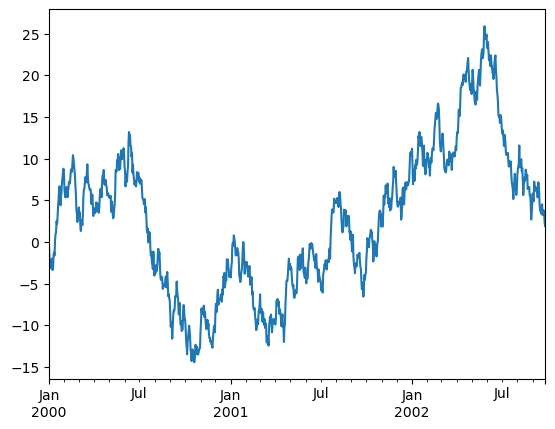

In [95]:
ts = pd.Series(np.random.randn(1000), index=pd.date_range("1/1/2000", periods=1000))
ts = ts.cumsum()
ts.plot();

**Note**

When using Jupyter, the plot will appear using `plot()`. Otherwise use `matplotlib.pyplot.show` to show it or `matplotlib.pyplot.savefig` to write it to a file.

`plot()` plots all columns:

<Figure size 640x480 with 0 Axes>

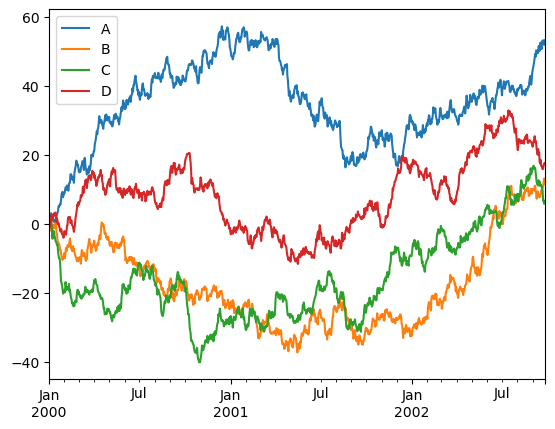

In [96]:
df = pd.DataFrame(
    np.random.randn(1000, 4), index=ts.index, columns=["A", "B", "C", "D"]
)
df = df.cumsum()
plt.figure();
df.plot();
plt.legend(loc='best');

## Importing and exporting data

### CSV

Writing to a csv file: using `DataFrame.to_csv()`

In [97]:
df = pd.DataFrame(np.random.randint(0, 5, (10, 5)))
df.to_csv("foo.csv")

Reading from a csv file: using `read_csv()`

In [98]:
pd.read_csv("foo.csv")

,Unnamed: 0,0,1,2,3,4
0,0,3,3,2,4,1
1,1,3,0,0,4,3
2,2,3,3,0,4,1
3,3,4,3,2,0,1
4,4,4,4,1,4,1
5,5,0,3,3,3,3
6,6,1,0,0,0,2
7,7,2,1,1,2,1
8,8,2,0,4,1,4
9,9,4,3,0,1,4


### Parquet

Writing to a Parquet file:

In [107]:
df.to_parquet("foo.parquet")

Reading from a Parquet file Store using `read_parquet()`:

In [108]:
pd.read_parquet("foo.parquet")

### Excel

Reading and writing to Excel.

Writing to an excel file using `DataFrame.to_excel()`:

In [110]:
df.to_excel("foo.xlsx", sheet_name="Sheet1")

Reading from an excel file using `read_excel()`:

In [111]:
pd.read_excel("foo.xlsx", "Sheet1", index_col=None, na_values=["NA"])

## Gotchas

If you are attempting to perform a boolean operation on a `Series` or `DataFrame` you might see an exception like:

```
if pd.Series([False, True, False]):
     print("I was true")
---------------------------------------------------------------------------
ValueError                                Traceback (most recent call last)
Cell In[143], line 1
----> 1 if pd.Series([False, True, False]):
      2      print("I was true")

File ~/work/pandas/pandas/pandas/core/generic.py:1501, in NDFrame.__bool__(self)
   1499     @final
   1500     def __bool__(self) -> NoReturn:
-> 1501         raise ValueError(
   1502             f"The truth value of a {type(self).__name__} is ambiguous. "
   1503             "Use a.empty, a.bool(), a.item(), a.any() or a.all()."
   1504         )

ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().
```

See the pandas documentation sections on Comparisons and Gotchas for an explanation and what to do.